# ch02_3. MNIST MLP 과적합과 Dropout

## 개요

- Underfitting(언더피팅, 과소적합), 적정 학습, Overfitting(오버피팅, 과적합)을 구분합니다.
- 일반화 간격을 이용해 훈련 정확도와 검증 정확도의 차이를 비교합니다.

## 공통 설정

데이터·모델·이미지 폴더 위치를 지정합니다.

In [1]:
from pathlib import Path

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
PNG_DIR = Path("png")

DATA_DIR.mkdir(exist_ok=True)

MODEL_DIR.mkdir(exist_ok=True)
PNG_DIR.mkdir(exist_ok=True)

print("데이터 폴더:", DATA_DIR)
print("모델 폴더  :", MODEL_DIR)
print("이미지 폴더:", PNG_DIR)


데이터 폴더: data
모델 폴더  : models
이미지 폴더: png


## 공통 import

In [2]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import (
    DataLoader,
    random_split,
)
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

### 1) 실행 장치 확인

```text
MNIST 데이터 준비
→ 실습용 훈련 8,000개·검증 2,000개 구성
→ 기본 MLP 학습
→ Dropout MLP 학습
→ 훈련·검증 손실과 정확도 비교
→ 일반화 간격 확인
→ 검증 데이터로 모델 선택
→ 테스트 데이터 최종 평가
→ Checkpoint 저장
```

MNIST는 비교적 쉬운 데이터입니다.

과적합을 더 쉽게 관찰하기 위해:

- 전체 60,000개 중 훈련 데이터 8,000개만 사용
- 은닉층을 비교적 크게 구성
- 기본 MLP와 Dropout MLP를 같은 조건으로 비교

실제 프로젝트에서 데이터를 일부러 줄이는 것은 과적합 해결 방법이 아닙니다.

| 상태 | 훈련 성능 | 검증 성능 | 해석 |
|---|---|---|---|
| 과소적합 | 낮음 | 낮음 | 모델 또는 학습이 부족 |
| 적정 학습 | 높음 | 높음 | 새로운 데이터에도 잘 일반화 |
| 과적합 | 매우 높음 | 상대적으로 낮음 | 훈련 데이터를 지나치게 암기 |

과적합의 대표적인 흐름:

```text
훈련 손실은 계속 감소
+
검증 손실은 정체하거나 증가
+
훈련 정확도와 검증 정확도의 차이가 커짐
→ 과적합 가능성
```

일반화 간격:

```text
일반화 간격 = 훈련 정확도 - 검증 정확도
```

일반화 간격이 클수록 훈련 데이터에 지나치게 맞춰졌을 가능성이 있습니다.

GPU를 사용할 수 있으면 CUDA(쿠다)를 사용하고, 그렇지 않으면 CPU를 사용합니다.

In [3]:
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

사용 장치: cuda


### 2) 데이터 분리

`ToTensor()`와 Normalize(노멀라이즈, 정규화)를 함께 사용합니다.

```text
원래 픽셀값
→ ToTensor로 0~1 범위 변환
→ MNIST 평균과 표준편차로 정규화
```

정규화 기준:

- 평균: `0.1307`
- 표준편차: `0.3081`

기본 MLP와 Dropout MLP에는 동일한 데이터를 사용합니다.

In [4]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(
            (0.1307,),
            (0.3081,),
        ),
    ]
)

full_train_dataset = datasets.MNIST(
    root=str(DATA_DIR / "torchvision"),
    train=True,
    transform=transform,
    download=True,
)

test_dataset = datasets.MNIST(
    root=str(DATA_DIR / "torchvision"),
    train=False,
    transform=transform,
    download=True,
)

split_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_dataset, validation_dataset, _ = random_split(
    full_train_dataset,
    [8_000, 2_000, 50_000],
    generator=split_generator,
)

print("실습용 훈련 데이터:", len(train_dataset))

print("검증 데이터:", len(validation_dataset))

print("테스트 데이터:", len(test_dataset))

100.0%
100.0%
100.0%
100.0%

실습용 훈련 데이터: 8000
검증 데이터: 2000
테스트 데이터: 10000


### 3) 배치 데이터 확인

두 모델을 공정하게 비교하려면 다음 조건을 같게 유지해야 합니다.

- 같은 훈련 데이터
- 같은 검증 데이터
- 같은 초기 가중치
- 같은 Batch Size(배치 사이즈)
- 같은 미니배치 순서
- 같은 Optimizer와 학습률
- 같은 Epoch 수

각 모델을 학습할 때 같은 Seed를 가진 `DataLoader`를 새로 만듭니다.

In [5]:
BATCH_SIZE = 128

NUMBER_OF_EPOCHS = 15

def make_train_loader():
    loader_generator = torch.Generator().manual_seed(
        RANDOM_SEED
    )

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=loader_generator,
    )

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

sample_images, sample_labels = next(
    iter(make_train_loader())
)

print("배치 이미지 shape:", sample_images.shape)

print("배치 정답 shape:", sample_labels.shape)

배치 이미지 shape: torch.Size([128, 1, 28, 28])
배치 정답 shape: torch.Size([128])


### 4) 모델 구성

두 모델은 Dropout 비율만 다릅니다.

```text
기본 MLP
Flatten
→ Linear(784, 512)
→ ReLU
→ Dropout(0.0)
→ Linear(512, 256)
→ ReLU
→ Dropout(0.0)
→ Linear(256, 10)

Dropout MLP
Flatten
→ Linear(784, 512)
→ ReLU
→ Dropout(0.3)
→ Linear(512, 256)
→ ReLU
→ Dropout(0.3)
→ Linear(256, 10)
```

`Dropout(0.3)`은 학습 중 각 Dropout 위치의 출력 약 30%를 무작위로 0으로 만듭니다.

가중치나 뉴런을 영구적으로 삭제하는 것은 아닙니다.

In [6]:
def make_model(dropout_probability):
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 512),
        nn.ReLU(),
        nn.Dropout(dropout_probability),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Dropout(dropout_probability),
        nn.Linear(256, 10),
    )

torch.manual_seed(RANDOM_SEED)

initial_model = make_model(
    dropout_probability=0.0
)

initial_state = copy.deepcopy(
    initial_model.state_dict()
)

basic_model = make_model(
    dropout_probability=0.0
).to(device)

dropout_model = make_model(
    dropout_probability=0.3
).to(device)

basic_model.load_state_dict(initial_state)

dropout_model.load_state_dict(initial_state)

parameter_count = sum(
    parameter.numel()
    for parameter in basic_model.parameters()
)

print("기본 MLP 파라미터 수:", f"{parameter_count:,}")

print("Dropout MLP 파라미터 수:", f"{parameter_count:,}")

기본 MLP 파라미터 수: 535,818
Dropout MLP 파라미터 수: 535,818


### 5) Loss 함수와 Optimizer 설정

검증과 테스트에서는 다음 기준을 사용합니다.

- `model.eval()`로 평가 모드 전환
- `torch.no_grad()`로 기울기 계산 중지
- 평균 손실 계산
- 정확도 계산

In [7]:
loss_function = nn.CrossEntropyLoss()

### 6) 평가 함수 정의

In [8]:
def evaluate_model(
    model,
    data_loader,
):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = loss_function(
                logits,
                labels,
            )

            predictions = logits.argmax(
                dim=1
            )

            loss_sum += (
                loss.item()
                * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = loss_sum / total
    accuracy = correct / total

    return average_loss, accuracy

### 7) 모델 학습

각 모델은 같은 절차로 학습합니다.

```text
같은 초기 가중치 적용
→ 같은 미니배치 순서 사용
→ Adam으로 15 Epoch 학습
→ 매 Epoch 검증
→ 최고 검증 정확도 가중치 저장
```

검증 정확도가 같으면 검증 손실이 더 낮은 Epoch를 선택합니다.

In [9]:
def train_model(
    model,
    model_name,
):
    train_loader = make_train_loader()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
    )

    history = {
        "train_loss": [],
        "validation_loss": [],
        "train_accuracy": [],
        "validation_accuracy": [],
    }

    best_validation_accuracy = -1.0
    best_validation_loss = float("inf")
    best_epoch = 0

    best_state = copy.deepcopy(
        model.state_dict()
    )

    print()
    print(f"[{model_name}] 학습 시작")

    for epoch in range(
        1,
        NUMBER_OF_EPOCHS + 1,
    ):
        model.train()

        loss_sum = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(images)

            loss = loss_function(
                logits,
                labels,
            )

            loss.backward()
            optimizer.step()

            predictions = logits.argmax(
                dim=1
            )

            loss_sum += (
                loss.item()
                * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

        train_loss = loss_sum / total
        train_accuracy = correct / total

        validation_loss, validation_accuracy = (
            evaluate_model(
                model,
                validation_loader,
            )
        )

        history["train_loss"].append(
            train_loss
        )

        history["validation_loss"].append(
            validation_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["validation_accuracy"].append(
            validation_accuracy
        )

        is_better = (
            validation_accuracy
            > best_validation_accuracy
            or (
                validation_accuracy
                == best_validation_accuracy
                and validation_loss
                < best_validation_loss
            )
        )

        if is_better:
            best_validation_accuracy = (
                validation_accuracy
            )

            best_validation_loss = (
                validation_loss
            )

            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch:>2d}/{NUMBER_OF_EPOCHS} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Accuracy {train_accuracy:.4f} | "
            f"Validation Loss {validation_loss:.4f} | "
            f"Validation Accuracy {validation_accuracy:.4f}"
        )

    model.load_state_dict(
        best_state
    )

    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "best_validation_accuracy": best_validation_accuracy,
    }

### 8) 기본 MLP 학습

Dropout 비율은 `0.0`입니다.

훈련 손실은 계속 감소하지만 검증 손실이 다시 증가하는지 관찰합니다.

In [10]:
basic_result = train_model(
    model=basic_model,
    model_name="기본 MLP",
)


[기본 MLP] 학습 시작
Epoch  1/15 | Train Loss 0.6033 | Train Accuracy 0.8249 | Validation Loss 0.2858 | Validation Accuracy 0.9150
Epoch  2/15 | Train Loss 0.2401 | Train Accuracy 0.9264 | Validation Loss 0.2103 | Validation Accuracy 0.9330
Epoch  3/15 | Train Loss 0.1461 | Train Accuracy 0.9551 | Validation Loss 0.1974 | Validation Accuracy 0.9395
Epoch  4/15 | Train Loss 0.0980 | Train Accuracy 0.9704 | Validation Loss 0.1634 | Validation Accuracy 0.9475
Epoch  5/15 | Train Loss 0.0702 | Train Accuracy 0.9785 | Validation Loss 0.1638 | Validation Accuracy 0.9490
Epoch  6/15 | Train Loss 0.0478 | Train Accuracy 0.9868 | Validation Loss 0.1420 | Validation Accuracy 0.9590
Epoch  7/15 | Train Loss 0.0278 | Train Accuracy 0.9930 | Validation Loss 0.1379 | Validation Accuracy 0.9620
Epoch  8/15 | Train Loss 0.0194 | Train Accuracy 0.9954 | Validation Loss 0.1798 | Validation Accuracy 0.9580
Epoch  9/15 | Train Loss 0.0099 | Train Accuracy 0.9981 | Validation Loss 0.1466 | Validation Accuracy 0

### 9) Dropout MLP 학습

모델 구조와 학습 조건은 그대로 유지하고 Dropout 비율만 `0.3`으로 변경합니다.

Dropout 때문에 훈련 정확도는 기본 MLP보다 낮을 수 있습니다.

중요한 비교 기준은 다음과 같습니다.

- 검증 정확도
- 검증 손실
- 일반화 간격

In [11]:
dropout_result = train_model(
    model=dropout_model,
    model_name="Dropout MLP",
)


[Dropout MLP] 학습 시작
Epoch  1/15 | Train Loss 0.7027 | Train Accuracy 0.7867 | Validation Loss 0.2913 | Validation Accuracy 0.9105
Epoch  2/15 | Train Loss 0.2933 | Train Accuracy 0.9080 | Validation Loss 0.2249 | Validation Accuracy 0.9325
Epoch  3/15 | Train Loss 0.2060 | Train Accuracy 0.9345 | Validation Loss 0.2027 | Validation Accuracy 0.9335
Epoch  4/15 | Train Loss 0.1511 | Train Accuracy 0.9514 | Validation Loss 0.1942 | Validation Accuracy 0.9400
Epoch  5/15 | Train Loss 0.1254 | Train Accuracy 0.9605 | Validation Loss 0.1537 | Validation Accuracy 0.9535
Epoch  6/15 | Train Loss 0.1064 | Train Accuracy 0.9675 | Validation Loss 0.1487 | Validation Accuracy 0.9540
Epoch  7/15 | Train Loss 0.0760 | Train Accuracy 0.9755 | Validation Loss 0.1517 | Validation Accuracy 0.9550
Epoch  8/15 | Train Loss 0.0731 | Train Accuracy 0.9766 | Validation Loss 0.1506 | Validation Accuracy 0.9525
Epoch  9/15 | Train Loss 0.0556 | Train Accuracy 0.9819 | Validation Loss 0.1547 | Validation Accur

### 10) 기본 MLP의 손실 곡선

과적합 가능성:

```text
훈련 손실 계속 감소
+
검증 손실 증가
```

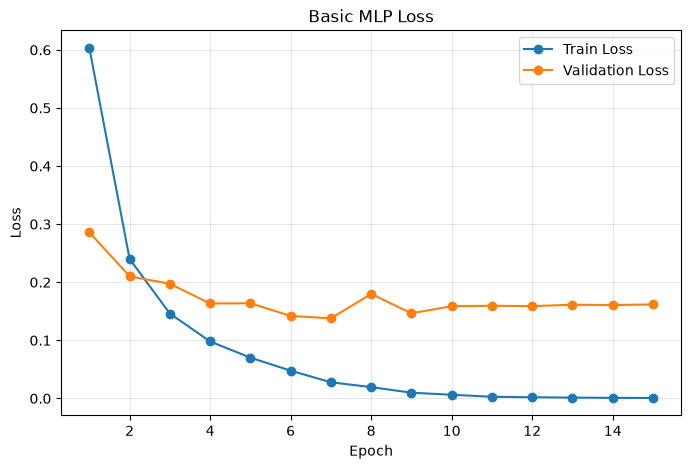

In [12]:
epoch_numbers = range(
    1,
    NUMBER_OF_EPOCHS + 1,
)

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    basic_result["history"]["train_loss"],
    marker="o",
    label="Train Loss",
)

plt.plot(
    epoch_numbers,
    basic_result["history"][
        "validation_loss"
    ],
    marker="o",
    label="Validation Loss",
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Basic MLP Loss")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 11) Dropout MLP의 손실 곡선

Dropout 적용 후 검증 손실이 더 안정적으로 유지되는지 확인합니다.

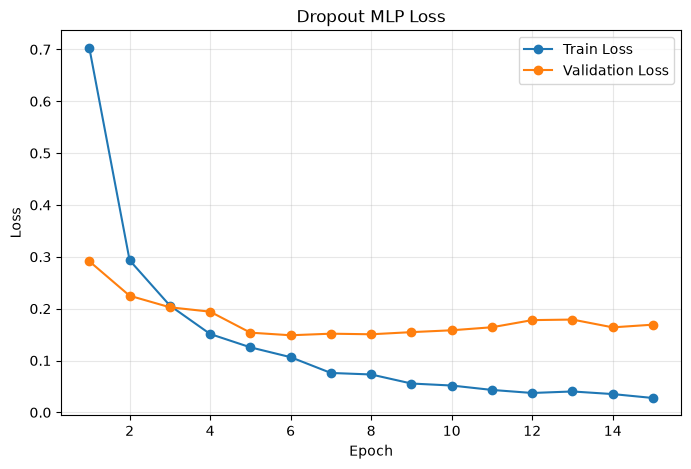

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    dropout_result["history"][
        "train_loss"
    ],
    marker="o",
    label="Train Loss",
)

plt.plot(
    epoch_numbers,
    dropout_result["history"][
        "validation_loss"
    ],
    marker="o",
    label="Validation Loss",
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Dropout MLP Loss")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 12) 두 모델의 검증 정확도 비교

Dropout의 훈련 정확도가 낮다는 이유만으로 성능이 나쁘다고 판단하지 않습니다.

새로운 데이터에 해당하는 검증 정확도를 함께 확인합니다.

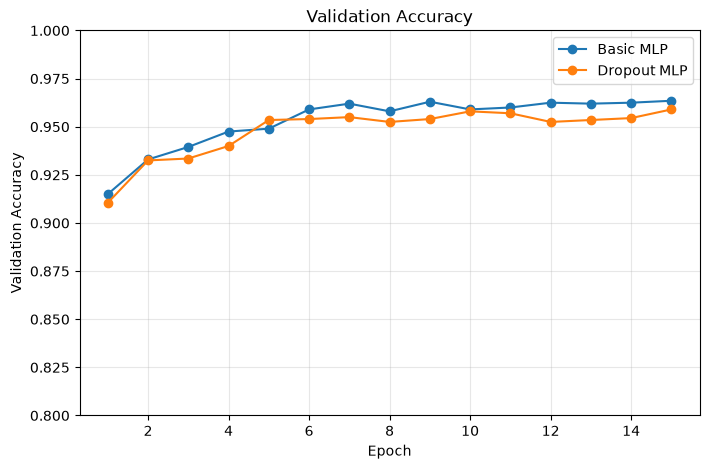

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    basic_result["history"][
        "validation_accuracy"
    ],
    marker="o",
    label="Basic MLP",
)

plt.plot(
    epoch_numbers,
    dropout_result["history"][
        "validation_accuracy"
    ],
    marker="o",
    label="Dropout MLP",
)

plt.xlabel("Epoch")

plt.ylabel("Validation Accuracy")

plt.title("Validation Accuracy")

plt.ylim(0.8, 1.0)

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 13) 일반화 간격 비교

각 Epoch의 일반화 간격:

```text
훈련 정확도 - 검증 정확도
```

간격이 클수록 훈련 데이터에 지나치게 맞춰졌을 가능성이 있습니다.

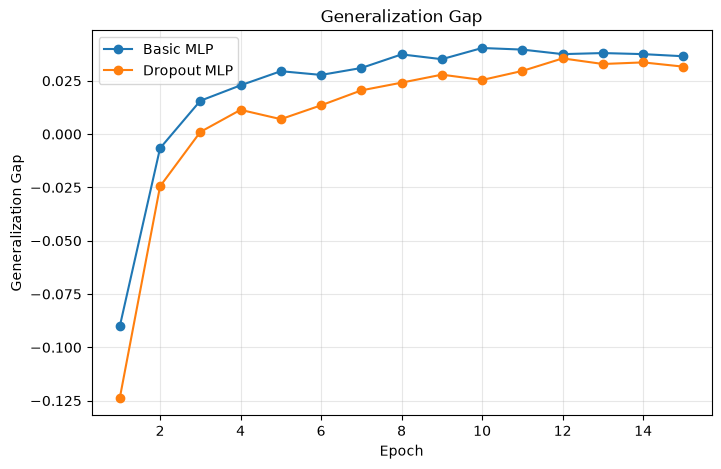

In [15]:
basic_gap = [
    train_accuracy - validation_accuracy
    for train_accuracy, validation_accuracy in zip(
        basic_result["history"]["train_accuracy"],
        basic_result["history"][
            "validation_accuracy"
        ],
    )
]

dropout_gap = [
    train_accuracy - validation_accuracy
    for train_accuracy, validation_accuracy in zip(
        dropout_result["history"][
            "train_accuracy"
        ],
        dropout_result["history"][
            "validation_accuracy"
        ],
    )
]

plt.figure(figsize=(8, 5))

plt.plot(
    epoch_numbers,
    basic_gap,
    marker="o",
    label="Basic MLP",
)

plt.plot(
    epoch_numbers,
    dropout_gap,
    marker="o",
    label="Dropout MLP",
)

plt.xlabel("Epoch")

plt.ylabel("Generalization Gap")

plt.title("Generalization Gap")

plt.grid(alpha=0.3)

plt.legend()

plt.show()

### 14) 결과 요약 함수

비교 항목:

- 최고 검증 정확도
- 최고 검증 Epoch
- 마지막 훈련 정확도
- 마지막 검증 정확도
- 마지막 일반화 간격

Dropout의 목적은 훈련 정확도를 최대화하는 것이 아니라 새로운 데이터에 대한 일반화를 개선하는 것입니다.

In [16]:
def summarize_result(
    model_name,
    result,
):
    history = result["history"]

    final_train_accuracy = history[
        "train_accuracy"
    ][-1]

    final_validation_accuracy = history[
        "validation_accuracy"
    ][-1]

    final_gap = (
        final_train_accuracy
        - final_validation_accuracy
    )

    return {
        "model_name": model_name,
        "best_epoch": result["best_epoch"],
        "best_validation_loss": result[
            "best_validation_loss"
        ],
        "best_validation_accuracy": result[
            "best_validation_accuracy"
        ],
        "final_train_accuracy": (
            final_train_accuracy
        ),
        "final_validation_accuracy": (
            final_validation_accuracy
        ),
        "final_gap": final_gap,
    }

### 15) 두 모델의 결과 요약

In [17]:
summaries = [
    summarize_result(
        "기본 MLP",
        basic_result,
    ),
    summarize_result(
        "Dropout MLP",
        dropout_result,
    ),
]

### 16) 요약 결과 출력

In [18]:
for summary in summaries:
    print()
    print(f"[{summary['model_name']}]")

    print(
        "최고 검증 Epoch:",
        summary["best_epoch"],
    )

    print(
        "최고 검증 손실:",
        f"{summary['best_validation_loss']:.4f}",
    )

    print(
        "최고 검증 정확도:",
        f"{summary['best_validation_accuracy']:.4f}",
    )

    print(
        "마지막 훈련 정확도:",
        f"{summary['final_train_accuracy']:.4f}",
    )

    print(
        "마지막 검증 정확도:",
        f"{summary['final_validation_accuracy']:.4f}",
    )

    print(
        "마지막 일반화 간격:",
        f"{summary['final_gap']:.4f}",
    )


[기본 MLP]
최고 검증 Epoch: 15
최고 검증 손실: 0.1618
최고 검증 정확도: 0.9635
마지막 훈련 정확도: 1.0000
마지막 검증 정확도: 0.9635
마지막 일반화 간격: 0.0365

[Dropout MLP]
최고 검증 Epoch: 15
최고 검증 손실: 0.1692
최고 검증 정확도: 0.9590
마지막 훈련 정확도: 0.9906
마지막 검증 정확도: 0.9590
마지막 일반화 간격: 0.0316


### 17) train()과 eval()에서 Dropout 동작 비교

같은 이미지를 여러 번 입력합니다.

- `model.train()`: Dropout이 동작하므로 출력이 달라질 수 있음
- `model.eval()`: Dropout이 꺼지므로 출력이 같음

평가 전에 `model.eval()`을 호출하지 않으면 예측 결과가 불안정해질 수 있습니다.

In [19]:
sample_images, _ = next(
    iter(validation_loader)
)

sample_image = sample_images[:1].to(device)

selected_dropout_model = dropout_result[
    "model"
]

selected_dropout_model.train()

train_output_1 = selected_dropout_model(
    sample_image
).detach().cpu()

train_output_2 = selected_dropout_model(
    sample_image
).detach().cpu()

selected_dropout_model.eval()

with torch.no_grad():
    eval_output_1 = selected_dropout_model(
        sample_image
    ).cpu()

    eval_output_2 = selected_dropout_model(
        sample_image
    ).cpu()

print(
    "train() 출력이 같은가?:",
    torch.allclose(
        train_output_1,
        train_output_2,
    ),
)

print(
    "eval() 출력이 같은가?:",
    torch.allclose(
        eval_output_1,
        eval_output_2,
    ),
)

train() 출력이 같은가?: False
eval() 출력이 같은가?: True


### 18) 검증 결과로 최종 모델 선택

선택 기준:

1. 최고 검증 정확도가 높은 모델
2. 정확도가 같으면 최고 검증 손실이 낮은 모델

테스트 데이터는 아직 사용하지 않습니다.

In [20]:
candidate_results = {
    "기본 MLP": basic_result,
    "Dropout MLP": dropout_result,
}

selected_model_name = max(
    candidate_results,
    key=lambda name: (
        candidate_results[name][
            "best_validation_accuracy"
        ],
        -candidate_results[name][
            "best_validation_loss"
        ],
    ),
)

selected_result = candidate_results[
    selected_model_name
]

selected_model = selected_result[
    "model"
]

selected_dropout_probability = (
    0.3
    if selected_model_name == "Dropout MLP"
    else 0.0
)

print("선택된 모델:", selected_model_name)

print(
    "선택 Epoch:",
    selected_result["best_epoch"],
)

print(
    "최고 검증 정확도:",
    f"{selected_result['best_validation_accuracy']:.4f}",
)

선택된 모델: 기본 MLP
선택 Epoch: 15
최고 검증 정확도: 0.9635


### 19) 테스트 성능 확인

검증 데이터로 모델을 선택한 뒤 선택된 모델 하나만 테스트 데이터로 평가합니다.

테스트 결과를 보고 다시 기본 MLP와 Dropout MLP 중 하나를 고르지 않습니다.

In [21]:
test_loss, test_accuracy = evaluate_model(
    selected_model,
    test_loader,
)

print("선택된 모델:", selected_model_name)

print(f"테스트 손실: {test_loss:.4f}")

print(f"테스트 정확도: {test_accuracy:.4f}")

print(
    f"맞힌 이미지 수: "
    f"{int(test_accuracy * len(test_dataset)):,}"
    f" / {len(test_dataset):,}"
)

선택된 모델: 기본 MLP
테스트 손실: 0.1700
테스트 정확도: 0.9618
맞힌 이미지 수: 9,618 / 10,000


### 20) 테스트 이미지 예측

테스트 이미지 5개에 대해 다음 내용을 확인합니다.

- 실제 정답
- 모델 예측
- 예측 확률

정규화된 이미지는 화면에 표시할 때 원래 범위에 가깝게 복원합니다.

In [22]:
test_images, test_labels = next(
    iter(test_loader)
)

selected_model.eval()

with torch.no_grad():
    test_logits = selected_model(
        test_images.to(device)
    )

    test_probabilities = torch.softmax(
        test_logits,
        dim=1,
    ).cpu()

    test_predictions = test_logits.argmax(
        dim=1
    ).cpu()

### 21) 예측 결과 시각화

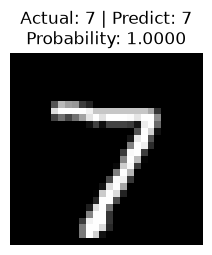

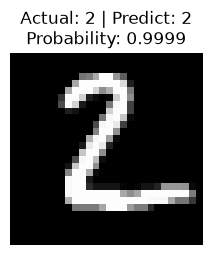

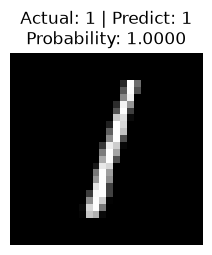

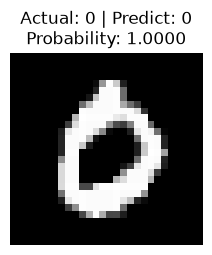

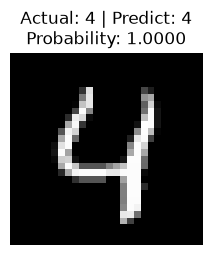

In [23]:
for index in range(5):
    actual = test_labels[index].item()
    predicted = test_predictions[index].item()

    confidence = test_probabilities[
        index,
        predicted,
    ].item()

    display_image = (
        test_images[index] * 0.3081
        + 0.1307
    )

    plt.figure(figsize=(2.5, 2.5))

    plt.imshow(
        display_image.squeeze().clamp(0, 1),
        cmap="gray",
    )

    plt.title(
        f"Actual: {actual} | "
        f"Predict: {predicted}\n"
        f"Probability: {confidence:.4f}"
    )

    plt.axis("off")
    plt.show()

### 22) Checkpoint 저장과 불러오기

Checkpoint에는 다음 정보를 저장합니다.

- 선택된 모델의 가중치
- 모델 이름
- Dropout 비율
- 은닉층 크기
- 정규화 평균과 표준편차
- 최고 검증 성능
- 테스트 성능

In [24]:
checkpoint_path = MODEL_DIR / "ch02_3_best_mnist_mlp.pt"

checkpoint = {
    "model_name": selected_model_name,
    "model_state_dict": (
        selected_model.state_dict()
    ),
    "dropout_probability": (
        selected_dropout_probability
    ),
    "hidden_sizes": [512, 256],
    "number_of_classes": 10,
    "normalization_mean": [0.1307],
    "normalization_std": [0.3081],
    "best_epoch": selected_result[
        "best_epoch"
    ],
    "validation_loss": selected_result[
        "best_validation_loss"
    ],
    "validation_accuracy": selected_result[
        "best_validation_accuracy"
    ],
    "test_loss": test_loss,
    "test_accuracy": test_accuracy,
}

torch.save(
    checkpoint,
    checkpoint_path,
)

loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True,
)

loaded_model = make_model(
    dropout_probability=loaded_checkpoint[
        "dropout_probability"
    ]
).to(device)

### 23) 불러온 모델 복원 확인

In [25]:
loaded_model.load_state_dict(
    loaded_checkpoint[
        "model_state_dict"
    ]
)

loaded_model.eval()

print("저장 파일:", checkpoint_path)

print(
    "불러온 모델:",
    loaded_checkpoint["model_name"],
)

print(
    "저장된 검증 정확도:",
    f"{loaded_checkpoint['validation_accuracy']:.4f}",
)

저장 파일: models/ch04_3_best_mnist_mlp.pt
불러온 모델: 기본 MLP
저장된 검증 정확도: 0.9635
